[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/01-time-series-data.ipynb)

# Time-Series Data: Index, Resampling and the Calendar

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Turn raw event records into a regular hourly series, filtering to the period first.</li>
<li>Resample to a coarser grain and detect partial buckets.</li>
<li>Find missing timestamps, explain a daylight-saving gap, and choose how to fill it.</li>
<li>Build lag and rolling-window columns and explain what each one looks like to a model.</li>
</ul>
</div>

**Prerequisites:** pandas basics (index, groupby). **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 30 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

A taxi dispatch team wants to know **how many pickups to expect in each hour of tomorrow**, so it can decide how many cabs to put on the road. The history it has is not a tidy table of hourly counts. It is millions of individual trips, each stamped with a pickup time. Turning that into a series you can forecast is the first job, and it is full of small traps: stray dates, hours that do not exist, and a calendar that is not as regular as it looks.

We use the New York City yellow-cab records (the TLC trip files). First, one month of raw trips.

In [2]:
from mlp_data import load_taxi

trips = load_taxi("2023-01")                          # about 3 million trips
pickup = trips["tpep_pickup_datetime"]
print(pickup.dtype, "|", f"{len(pickup):,} trips")
print("earliest:", pickup.min(), "| latest:", pickup.max())

datetime64[us] | 3,066,766 trips
earliest: 2008-12-31 23:01:42 | latest: 2023-02-01 00:56:53


The file is called *January 2023*, yet the earliest pickup is in **2008**. Some meters have a wrong clock. Before counting anything, find the trips that do not belong.

In [3]:
in_month = (pickup >= "2023-01-01") & (pickup < "2023-02-01")
stray = pickup[~in_month]
print(f"{len(stray)} of {len(pickup):,} trips fall outside January 2023")
print(stray.sort_values().dt.year.value_counts().sort_index().to_string())

48 of 3,066,766 trips fall outside January 2023
tpep_pickup_datetime
2008     2
2022    36
2023    10


Only a handful, but a handful of trips from 2008 would stretch the time axis over fourteen years and make a plot useless. **Rule: filter to the period you mean before you aggregate.**

## 1. From events to a series

A *time series* is a value observed at regular times. Our events are irregular (one per trip), so we choose a **grain**, here one hour, and count the events in each bucket. `floor("h")` rounds each timestamp down to the hour, and `value_counts` counts per hour.

In [4]:
hourly = (pickup[in_month].dt.floor("h")
          .value_counts().sort_index()
          .rename("pickups"))
hourly.index.name = "hour"
print(type(hourly.index).__name__, "| rows:", len(hourly), "| January has", 31 * 24, "hours")
hourly.head()

DatetimeIndex | rows: 744 | January has 744 hours


hour
2023-01-01 00:00:00    5336
2023-01-01 01:00:00    5752
2023-01-01 02:00:00    5097
2023-01-01 03:00:00    3952
2023-01-01 04:00:00    2501
Name: pickups, dtype: int64

This is exactly what `taxi_hourly` (from `mlp_data.timeseries`) does for any list of months, reading just the one column it needs and caching the result. We use it from here on, with **January to March 2023**, 90 days of demand.

In [5]:
y = taxi_hourly(["2023-01", "2023-02", "2023-03"])
assert y.loc["2023-01"].equals(hourly)                # the helper reproduces our hand-made version
print(f"{len(y):,} hourly values from {y.index[0]} to {y.index[-1]}")
y.describe().to_frame().T

2,159 hourly values from 2023-01-01 00:00:00 to 2023-03-31 23:00:00


,count,mean,std,min,25%,50%,75%,max
pickups,"2,159.00","4,346.55","2,431.22",155.00,"1,868.00","5,106.00","6,257.00","9,562.00"


The index is a `DatetimeIndex`. That is what makes the series special in pandas: you can **slice by date strings**, and the end is *inclusive* (unlike ordinary Python slices).

168 hours in the slice (7 x 24 = 168)


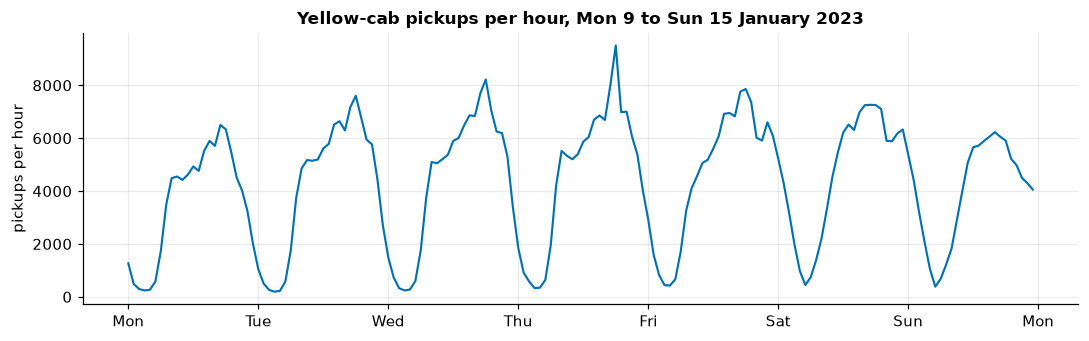

In [6]:
week = y["2023-01-09":"2023-01-15"]                   # Monday to Sunday, both ends included
print(len(week), "hours in the slice (7 x 24 = 168)")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(week.index, week.to_numpy(), lw=1.4)
ax.set(title="Yellow-cab pickups per hour, Mon 9 to Sun 15 January 2023", ylabel="pickups per hour")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a"))
plt.tight_layout(); plt.show()

Two rhythms are obvious: a **daily cycle** (quiet at 4am, busy in the evening) and a **weekly cycle** (the weekend looks different from weekdays). Nearly everything in forecasting is about those repeating patterns and what is left after you account for them.

## 2. Resampling: changing the grain

`resample` is `groupby` for time. Choose a coarser grain and say how to combine the values; for counts that is `sum`.

In [7]:
daily = y.resample("D").sum()
print(f"busiest day:  {daily.idxmax():%a %d %b} with {daily.max():,} pickups")
print(f"quietest day: {daily.idxmin():%a %d %b} with {daily.min():,} pickups")
daily.nsmallest(5).to_frame()

busiest day:  Thu 16 Mar with 124,026 pickups
quietest day: Mon 02 Jan with 65,777 pickups


,pickups
hour,
2023-01-02,65777
2023-01-01,76752
2023-02-20,79583
2023-01-16,80120
2023-01-30,83768


Four of the five quietest days are holidays: **New Year's Day, the Monday after it (the observed public holiday), Presidents' Day and Martin Luther King Day**. Holidays are information the series itself cannot tell you in advance, so later pages feed them to the model.

Now the trap. Weekly totals look like an easy use of `resample("W")`, but weeks are cut at **Sunday**, and our data does not start or end on one.

In [8]:
weekly = y.resample("W")
counts = weekly.size()                                # how many hourly rows landed in each bin
print(counts.iloc[[0, 1, -1]].to_string(), sep="")

hour
2023-01-01     24
2023-01-08    168
2023-04-02    120


The first "week" has just 24 rows (1 January was a Sunday) and the last has 120 (it ends on Friday 31 March). Their totals are far smaller than a full week's, and any chart or model that treats them as comparable is wrong. **Always check how many observations fed each bucket.**

## 3. Missing timestamps and the clock

A series on a regular grid has an entry for every hour. Does ours? `asfreq("h")` lays out the full grid and puts `NaN` wherever an hour is absent.

In [9]:
grid = y.asfreq("h")
missing = grid[grid.isna()]
print("expected hours:", len(grid), "| present:", len(y), "| missing:", len(missing))
print(missing.index.tolist())
y["2023-03-12 00:00":"2023-03-12 05:00"].to_frame()

expected hours: 2160 | present: 2159 | missing: 1
[Timestamp('2023-03-12 02:00:00')]


,pickups
hour,
2023-03-12 00:00:00,6111
2023-03-12 01:00:00,5231
2023-03-12 03:00:00,4267
2023-03-12 04:00:00,2530
2023-03-12 05:00:00,910


Exactly one hour is missing: **02:00 on Sunday 12 March 2023**. It is not that nobody took a taxi. On that date New York moved its clocks forward from 02:00 to 03:00, so 02:00 *never happened* on the wall clock. The timestamps in the file are **local wall-clock time with no time zone attached** (naive), so the skipped hour is simply absent. Two consequences:

- That Sunday has 23 hours, so its daily total is a little lower for a reason that has nothing to do with demand.
- In November the clocks go back and 01:00 happens **twice**. A naive timestamp cannot tell the two apart. (Our three months do not contain that date, but a year-long series does.)

pandas can attach the time zone and handle this explicitly:

In [10]:
ny = pd.date_range("2023-03-12 00:00", periods=6, freq="h", tz="America/New_York")
print(pd.DataFrame({"wall clock": ny, "UTC": ny.tz_convert("UTC")}).assign(offset=ny.strftime("%z")).to_string(index=False))

               wall clock                       UTC offset
2023-03-12 00:00:00-05:00 2023-03-12 05:00:00+00:00  -0500
2023-03-12 01:00:00-05:00 2023-03-12 06:00:00+00:00  -0500
2023-03-12 03:00:00-04:00 2023-03-12 07:00:00+00:00  -0400
2023-03-12 04:00:00-04:00 2023-03-12 08:00:00+00:00  -0400
2023-03-12 05:00:00-04:00 2023-03-12 09:00:00+00:00  -0400
2023-03-12 06:00:00-04:00 2023-03-12 10:00:00+00:00  -0400


In UTC the six hours are consecutive; on the wall clock one is skipped and the offset changes from -0500 to -0400. A common professional practice is to **store and model in UTC and convert to local time only to build calendar features** such as "hour of day". Here we keep the local naive clock, because that is what the data gives us and because *people's habits follow the wall clock*: the morning rush stays at 8am local time on both sides of the change.

For one missing hour out of 2,160 we simply fill the gap by linear interpolation so that the series has a regular grid, which every later page needs.

In [11]:
y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
assert y.notna().all() and len(y) == 90 * 24
print("filled value at 02:00:", round(y["2023-03-12 02:00"]), "(between", y["2023-03-12 01:00"], "and", y["2023-03-12 03:00"], ")")

filled value at 02:00: 4749 (between 5231.0 and 4267.0 )


<div class="admonition warning">
<p class="admonition-title">Filling is a modelling decision</p>
<p>Interpolating is fine for one hour that does not exist. It would be wrong for a sensor that was <em>switched off</em> for a day (you would be inventing a day of data), and wrong if "missing" really means "zero events", in which case fill with 0. Always ask what a gap means before choosing how to fill it, and keep a record of what you filled.</p>
</div>

## 4. Windows and shifts

Two operations carry most of the weight in time-series feature work. `shift(k)` moves the series down by *k* steps, so each row sees the value from *k* steps ago. `rolling(w)` computes a statistic over the last *w* steps.

In [12]:
demo = pd.DataFrame({"pickups": y})
demo["same hour yesterday"] = y.shift(24)
demo["same hour last week"] = y.shift(168)
demo["mean of last 24 h"] = y.rolling(24).mean()
print("leading NaNs:", demo.isna().sum().to_dict())
demo["2023-01-09 08:00":"2023-01-09 10:00"]

leading NaNs: {'pickups': 0, 'same hour yesterday': 24, 'same hour last week': 168, 'mean of last 24 h': 23}


,pickups,same hour yesterday,same hour last week,mean of last 24 h
hour,,,,
2023-01-09 08:00:00,"4,488.00","1,703.00","1,540.00","3,251.12"
2023-01-09 09:00:00,"4,550.00","2,569.00","2,325.00","3,333.67"
2023-01-09 10:00:00,"4,422.00","3,905.00","3,134.00","3,355.21"


The count above shows the warm-up: `shift(24)` is `NaN` for the first 24 rows (there is no yesterday on the first day), `shift(168)` for the first 168, and the rolling mean needs a full window so it is `NaN` for its first 23. Dropping or handling these warm-up rows is a routine step.

A subtlety: `rolling(168)` counts **rows**, while `rolling("7D")` counts **time**. They agree on a complete grid and disagree as soon as rows go missing. Compare them on the raw, un-filled series around the daylight-saving gap:

In [13]:
raw = taxi_hourly(["2023-01", "2023-02", "2023-03"])           # the 02:00 hour is absent here
by_rows = raw.rolling(168).mean()
by_time = raw.rolling("7D").mean()
day = "2023-03-14 12:00"
t = pd.Timestamp(day)
first_by_rows = raw.index[raw.index.get_loc(t) - 167]            # the oldest of the last 168 rows
first_by_time = raw.index[raw.index > t - pd.Timedelta("7D")][0]  # the oldest row inside the last 7 days
print(f"oldest value used at {day}: rolling(168) -> {first_by_rows},  rolling('7D') -> {first_by_time}")
print(f"rolling(168) = {by_rows[day]:,.1f}   rolling('7D') = {by_time[day]:,.1f}")

oldest value used at 2023-03-14 12:00: rolling(168) -> 2023-03-07 12:00:00,  rolling('7D') -> 2023-03-07 13:00:00
rolling(168) = 4,688.5   rolling('7D') = 4,681.1


With a hole in the data, "the last 168 observations" reach one hour further back in time than "the last seven days". Regularise first (as we did), then both mean the same thing.

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| A plot stretches back to 2008 | stray timestamps outside the period | filter to the period before aggregating |
| First and last "weeks" look tiny | `resample("W")` cuts at Sundays | check `.size()` per bucket; drop or flag partial buckets |
| A day has 23 or 25 hours | daylight-saving change in a naive local clock | model in UTC, or know the date and treat it |
| Missing hours break lag features | irregular grid | `asfreq` to the regular grid, then fill deliberately |
| `rolling(n)` and `rolling("nD")` disagree | rows versus time | regularise the grid first |
| Slice `s["a":"b"]` includes `b` | label slicing is inclusive | remember it when counting rows |

## Check yourself

<details class="question">
<summary>1. Why aggregate trips into hourly counts instead of forecasting trip by trip?</summary>

A forecast needs a **regular series with a fixed grain**; individual trips are irregular events. The grain should match the decision: dispatchers plan cabs by the hour, so hourly counts are the natural unit. A coarser grain (daily) would hide the within-day pattern they care about, and a finer one (per minute) would be mostly noise.

</details>

<details class="question">
<summary>2. Sunday 12 March 2023 has a lower total than the Sundays either side of it. Name one reason that is <em>not</em> about demand.</summary>

It has only **23 hours**: the clocks moved forward and 02:00 never existed. Part of the dip is a calendar artefact, which is why a model fed raw daily totals should know about such dates (or work in UTC).

</details>

<details class="question">
<summary>3. You see a gap of 36 hours in a sensor series. List two quite different things it could mean and how each changes the fix.</summary>

(a) The sensor was **offline**: the true value is unknown, so interpolating invents data. Better to leave it missing, or model the series with the gap, or drop the affected period. (b) **Nothing happened**, so the value is genuinely zero, such as no sales on a closed day: fill with 0. The same `NaN` needs a different treatment depending on the meaning, which you must find out from whoever produced the data.

</details>

## Exercises

<details class="question">
<summary>Compute the average number of pickups for each hour of the day on <em>weekdays</em> and on <em>weekends</em> separately. At which hour is the weekend ahead of the weekday? Predict first.</summary>

```python
by = y.groupby([y.index.dayofweek >= 5, y.index.hour]).mean().unstack(0)
by.columns = ["weekday", "weekend"]
ahead = by.index[by["weekend"] > by["weekday"]]
print(list(ahead))
```

The weekend is ahead at hours 0 to 4 (by a wide margin: about 5,400 against 1,800 pickups at midnight), and also, narrowly, at 1pm and 11pm. At night people are travelling home from an evening out, while weekday daytime is dominated by commuting and business trips. Two groups of days with different daily shapes is exactly why a single "hour of day" feature is not enough and a model also needs the day of week.

</details>

<details class="question">
<summary>Resample to weekly totals but keep only the weeks that have all 168 hours.</summary>

```python
w = y.resample("W")
full_weeks = w.sum()[w.size() == 168]
print(len(full_weeks), "complete weeks")
```

Of the 14 week-bins, 12 are complete: the first (only 1 January) and the last (27 to 31 March) are partial. Filtering on the bucket size is the safe way to drop them.

</details>

<details class="question">
<summary>Convert the series to UTC. Does the daylight-saving gap disappear? What happens to the hour-of-day feature?</summary>

```python
raw = taxi_hourly(["2023-01", "2023-02", "2023-03"])
utc = raw.tz_localize("America/New_York").tz_convert("UTC")
print(utc.index.to_series().diff().value_counts())  # use the raw series: see text
```

On the raw series (before filling) the missing hour is a hole on the wall clock but **not** in UTC: all 2,158 steps are exactly one hour. After our interpolation the series contains an invented 02:00 on 12 March, a time that does not exist locally, so `tz_localize` raises an error complaining about a nonexistent time. That is a good argument for localising *before* filling. In UTC you would compute the "hour of day" feature from the local time (`tz_convert("America/New_York").hour`), not from the UTC hour.

</details>

## Recap

- Turn events into a series by choosing a **grain** and counting; **filter to the intended period first**.
- A `DatetimeIndex` gives date-string slicing (end inclusive), `resample` and time-based windows.
- Check **bucket sizes** (`size()`), partial buckets mislead.
- Naive local timestamps hide **daylight-saving** gaps and repeats; know them, or model in UTC.
- A gap is a modelling decision: interpolate, zero-fill or leave missing, depending on what it means.
- `shift` and `rolling` are how history becomes features: the next pages are careful about *which* history is allowed.

**Next:** *Trend, seasonality and stationarity*.